#2B. Building an NLP DL model, build a DL model that can distinguish emotions from texts.

Read data

In [3]:
# Basic libraries
import pandas as pd
import numpy as np

# Visualization (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re
import string

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


In [4]:
import zipfile

zip_path = "/content/2B.zip"
extract_path = "/content/data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Done Unzip!")


Done Unzip!


In [5]:
#folder check
!ls /content/data

2B


In [6]:
!ls /content/data/2B

text_emotions.tsv


In [7]:
import pandas as pd

df = pd.read_csv('/content/data/2B/text_emotions.tsv', sep='\t')
df.head()

,id,text,label
0,411553,i feel rebellious and i like it,anger
1,18079,i feel completely agitated and full of blame,anger
2,282107,i feel like a witch bc im aggravated and i wan...,anger
3,49946,i feel really bitchy for doing this but im rea...,anger
4,96367,i feel rude but i move past it immediately,anger


###2a. Perform EDA on the provided dataset & state the discovered issues! Identify the key characteristics of each class!

In [8]:
df.head()

,id,text,label
0,411553,i feel rebellious and i like it,anger
1,18079,i feel completely agitated and full of blame,anger
2,282107,i feel like a witch bc im aggravated and i wan...,anger
3,49946,i feel really bitchy for doing this but im rea...,anger
4,96367,i feel rude but i move past it immediately,anger


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250084 entries, 0 to 250083
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   id      250084 non-null  int64 
 1   text    250084 non-null  object
 2   label   250084 non-null  object
dtypes: int64(1), object(2)
memory usage: 5.7+ MB


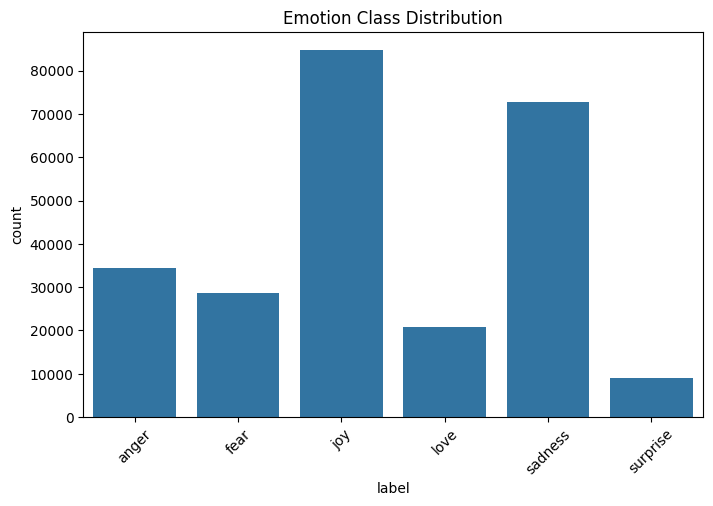

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='label')
plt.title('Emotion Class Distribution')
plt.xticks(rotation=45)
plt.show()


Data Imbalanced

Kelas joy merupakan kelas dominan dengan jumlah data paling besar.

Kelas sadness juga memiliki jumlah sampel yang tinggi.

Kelas surprise merupakan kelas dengan jumlah data paling sedikit.

Kelas anger, fear, dan love berada pada kategori menengah.

Ketidakseimbangan kelas ini berpotensi menyebabkan model lebih bias terhadap kelas mayoritas dan menurunkan performa prediksi pada kelas minoritas, terutama surprise.

In [11]:
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
df['text_length'].describe()

,text_length
count,250084.000000
mean,19.211337
std,11.054051
min,1.000000
25%,11.000000
50%,17.000000
75%,25.000000
max,178.000000


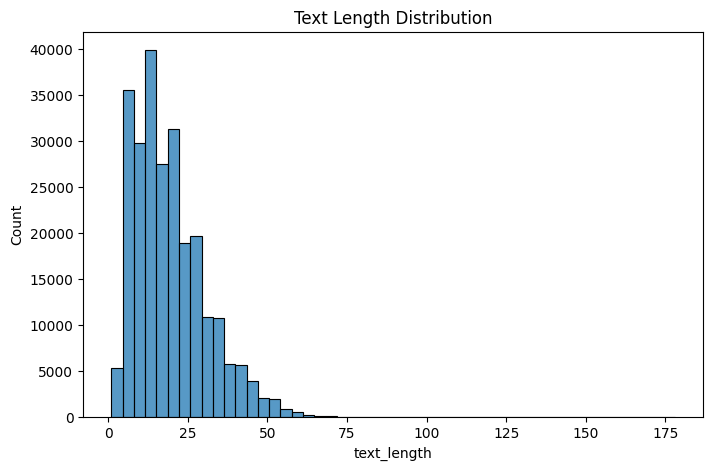

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['text_length'], bins=50)
plt.title('Text Length Distribution')
plt.show()


Distribusi menunjukkan pola right-skewed, di mana sebagian besar teks pendek dan hanya sedikit teks yang sangat panjang.

Variasi panjang teks yang cukup besar menunjukkan adanya teks yang sangat pendek dengan konteks terbatas serta teks yang sangat panjang yang berpotensi mengandung noise.

- Diperlukan padding dan truncation

- Pemilihan maksimum sequence length harus mempertimbangkan trade-off antara efisiensi komputasi dan pelestarian informasi

In [13]:
df.groupby('label')['text_length'].mean()

,text_length
label,
anger,19.031957
fear,18.981835
joy,19.533767
love,20.784536
sadness,18.490084
surprise,19.798731


### 2b. Based on the discovered issues, pre-process the text data to reduce noises in the data!

In [14]:
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize


In [15]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [16]:
stop_words = set(stopwords.words('english'))
# stopwords = kata umum (is, am, the, and) → tidak membawa makna emosi

lemmatizer = WordNetLemmatizer()
# lemmatizer = mengubah kata ke bentuk dasar (feels → feel)


In [17]:
def preprocess_text(text):
    """
    Fungsi ini digunakan untuk membersihkan teks
    agar noise berkurang dan siap digunakan untuk modeling
    """

    # 1. Case folding
    # Mengubah semua huruf menjadi lowercase
    # Tujuan: menyamakan bentuk kata (Happy = happy)
    text = text.lower()

    # 2. Remove URL
    # Menghapus link karena tidak relevan untuk analisis emosi
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # 3. Remove numbers
    # Angka biasanya tidak membawa informasi emosi
    text = re.sub(r'\d+', '', text)

    # 4. Remove punctuation & special characters
    # Menghapus tanda baca dan simbol (!@#$)
    text = re.sub(r'[^\w\s]', '', text)

    # 5. Tokenization
    # Memecah kalimat menjadi kata-kata
    tokens = word_tokenize(text)

    # 6. Stopword removal
    # Menghapus kata umum yang tidak bermakna emosional
    tokens = [word for word in tokens if word not in stop_words]

    # 7. Lemmatization
    # Mengubah kata ke bentuk dasarnya
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # 8. Join token kembali menjadi kalimat
    text = ' '.join(tokens)

    return text


In [18]:
df['clean_text'] = df['text'].apply(preprocess_text)

In [19]:
# 5. Hitung panjang teks setelah preprocessing

df['clean_text_length'] = df['clean_text'].apply(lambda x: len(x.split()))


In [20]:
# 6. Drop baris dengan clean_text kosong

df = df[df['clean_text'].str.strip() != '']


In [21]:
# Lihat 5 contoh sebelum & sesudah preprocessing
df[['text', 'clean_text']].head()


,text,clean_text
0,i feel rebellious and i like it,feel rebellious like
1,i feel completely agitated and full of blame,feel completely agitated full blame
2,i feel like a witch bc im aggravated and i wan...,feel like witch bc im aggravated want go like ...
3,i feel really bitchy for doing this but im rea...,feel really bitchy im really iffy read journal...
4,i feel rude but i move past it immediately,feel rude move past immediately


In [22]:
df['text_length'] = df['text'].apply(lambda x: len(x.split()))
df['clean_text_length'] = df['clean_text'].apply(lambda x: len(x.split()))

df[['text_length', 'clean_text_length']].describe()


,text_length,clean_text_length
count,250074.000000,250074.000000
mean,19.212041,9.355351
std,11.053709,5.240527
min,1.000000,1.000000
25%,11.000000,5.000000
50%,17.000000,8.000000
75%,25.000000,12.000000
max,178.000000,79.000000


In [23]:
# Jumlah teks kosong
(df['clean_text'].str.strip() == '').sum()

np.int64(0)

In [24]:
# Unique words sebelum preprocessing
vocab_before = set(" ".join(df['text']).split())

# Unique words sesudah preprocessing
vocab_after = set(" ".join(df['clean_text']).split())

print("Vocabulary before:", len(vocab_before))
print("Vocabulary after :", len(vocab_after))


Vocabulary before: 59108
Vocabulary after : 52841


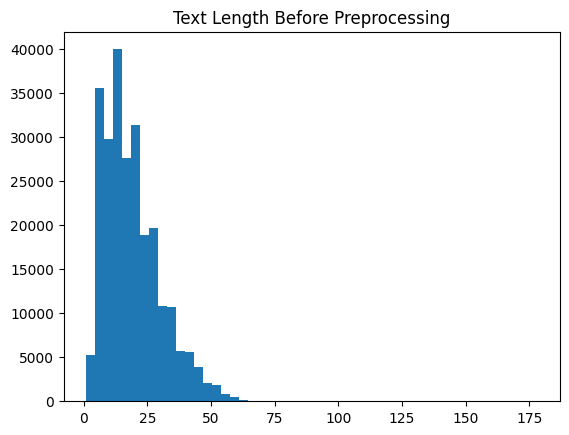

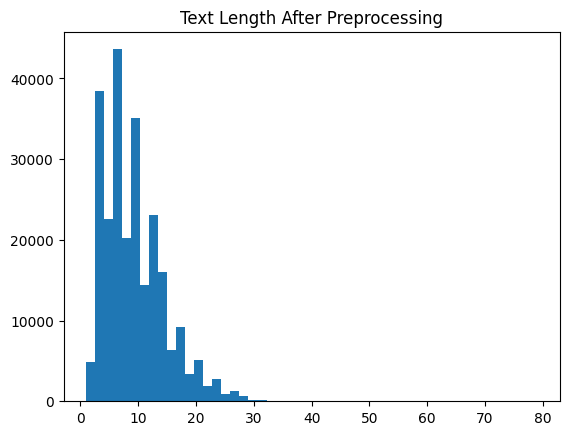

In [25]:
import matplotlib.pyplot as plt

plt.hist(df['text_length'], bins=50)
plt.title("Text Length Before Preprocessing")
plt.show()

plt.hist(df['clean_text_length'], bins=50)
plt.title("Text Length After Preprocessing")
plt.show()


Distribusi panjang teks setelah preprocessing tetap menunjukkan pola right-skewed yang serupa dengan data awal. Hal ini menunjukkan bahwa preprocessing tidak mengubah karakteristik alami data, melainkan hanya menghilangkan noise seperti stopwords dan karakter tidak relevan, sehingga struktur semantik utama tetap terjaga.

### 2c. Build a Bidirectional GRU model with an Embedding layer

In [26]:
# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, GRU, Bidirectional, Dense, Dropout
)

# Text processing
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Data splitting & encoding
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical


In [27]:
max_len = 40
embedding_dim = 64
batch_size = 128
epochs = 15

In [28]:
# Membuat tokenizer
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

# Ubah teks ke sequence angka
X = tokenizer.texts_to_sequences(df['clean_text'])

# Samakan panjang kalimat
X = pad_sequences(
    X,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

# Vocab size = jumlah kata unik
vocab_size = len(tokenizer.word_index) + 1

print("Vocab size:", vocab_size)
print("Input shape:", X.shape)

Vocab size: 52843
Input shape: (250074, 40)


In [29]:
# Encode label
le = LabelEncoder()
y = le.fit_transform(df['label'])

# One-hot encoding
y = to_categorical(y)

print("Label shape:", y.shape)

Label shape: (250074, 6)


In [30]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [31]:
tf.keras.backend.clear_session()

In [32]:
model = Sequential([
    # Mendefinisikan bentuk input
    Input(shape=(max_len,)),

    # Embedding layer
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),

    # GRU layer 1 (1024 neuron)
    Bidirectional(
        GRU(1024, return_sequences=True)
    ),

    # GRU layer 2 (512 neuron = N/2)
    Bidirectional(
        GRU(512)
    ),

    # Regularization
    Dropout(0.5),

    # Output layer
    Dense(y.shape[1], activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 64)         │     3,381,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 40, 2048)       │     6,696,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 1024)           │     7,870,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         6,150 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,955,526 (68.49 MB)

 Trainable params: 17,955,526 (68.49 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size
)

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 261s 163ms/step - accuracy: 0.8200 - loss: 0.4425 - val_accuracy: 0.9371 - val_loss: 0.1052
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 256s 164ms/step - accuracy: 0.9406 - loss: 0.1027 - val_accuracy: 0.9393 - val_loss: 0.0987
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 256s 164ms/step - accuracy: 0.9436 - loss: 0.0957 - val_accuracy: 0.9378 - val_loss: 0.1126
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 256s 164ms/step - accuracy: 0.9447 - loss: 0.0916 - val_accuracy: 0.9369 - val_loss: 0.1074
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 256s 164ms/step - accuracy: 0.9472 - loss: 0.0891 - val_accuracy: 0.9347 - val_loss: 0.1190
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 256s 164ms/step - accuracy: 0.9501 - loss: 0.0869 - val_accuracy: 0.9326 - val_loss: 0.1255
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 256s 164ms/step - accuracy: 0.9525 - loss: 0.0810 - val_accuracy: 0.9325 - val_loss: 0.1228
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 254s 162ms/step - ac

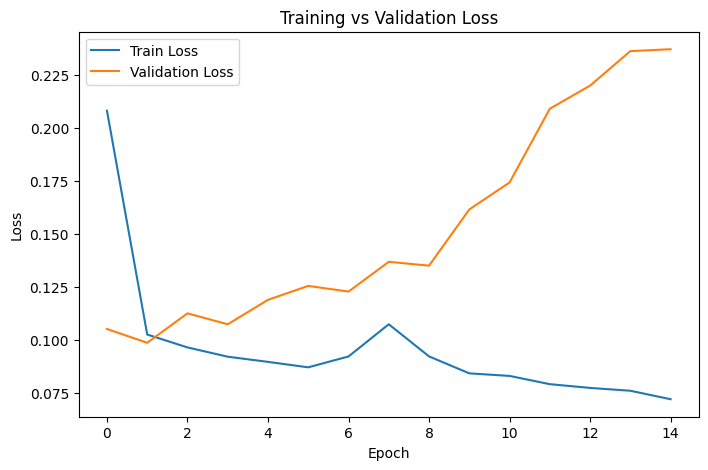

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training vs Validation Loss')
plt.show()


###2e. Evaluate both models on a test dataset. Analyze the results & make a clear conclusion!

In [35]:
import numpy as np

# prediksi probabilitas
y_pred_prob = model.predict(X_val, batch_size=128)

# ambil kelas dengan probabilitas tertinggi
y_pred = np.argmax(y_pred_prob, axis=1)

# label asli (jika y_val one-hot encoded)
y_true = np.argmax(y_val, axis=1)

391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step


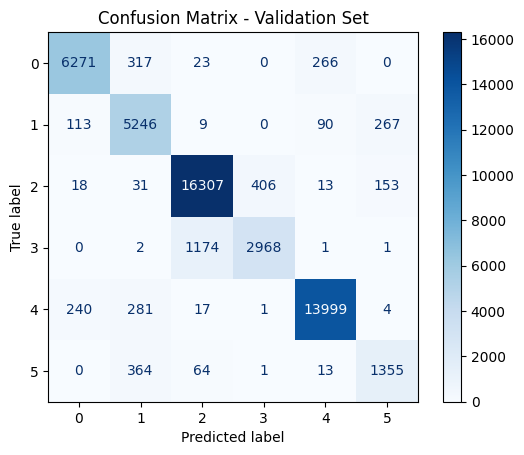

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

# tampilkan
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Validation Set")
plt.show()

In [39]:
from sklearn.metrics import classification_report, accuracy_score

acc = accuracy_score(y_true, y_pred)
print(f"Validation Accuracy: {acc:.4f}\n")
print(classification_report(y_true, y_pred))

Validation Accuracy: 0.9226

              precision    recall  f1-score   support

           0       0.94      0.91      0.93      6877
           1       0.84      0.92      0.88      5725
           2       0.93      0.96      0.94     16928
           3       0.88      0.72      0.79      4146
           4       0.97      0.96      0.97     14542
           5       0.76      0.75      0.76      1797

    accuracy                           0.92     50015
   macro avg       0.89      0.87      0.88     50015
weighted avg       0.92      0.92      0.92     50015



akurasi validasi model sebesar 92,26%. Ini menunjukkan kinerja keseluruhan yang kuat. Kelas dengan jumlah data yang lebih besar (joy dan sadness) berhasil diklasifikasikan dengan nilai presisi dan recall yang tinggi. Namun, kelas dengan jumlah data yang lebih sedikit (love dan surprise) menunjukkan nilai recall yang lebih rendah, yang menunjukkan adanya ketidakseimbangan kelas serta semantic overlap antar kelas. peningkatan nilai validation loss setelah beberapa epoch awal juga menunjukkan adanya overfitting, di mana model cenderung lebih memprioritaskan kelas mayoritas dibandingkan kelas minoritas.